# 01 Issuer fundamentals: capex, cash flow, leverage and maturities
Reads datasets built by `src/build_datasets.py` and outputs from `src/run_analysis.py`. No data are created here. Category A (computed from SEC EDGAR XBRL).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
T = ROOT / 'outputs' / 'tables'; F = ROOT / 'outputs' / 'figures'
def show_md(name): display(Markdown((T / f'{name}.md').read_text()))
def show_fig(name): display(Image(filename=str(F / f'{name}.png'), width=900))

In [2]:
annual = pd.read_csv(ROOT/'data/processed/issuer_annual_10k.csv', parse_dates=['fiscal_period_end'])
annual.pivot(index='fiscal_year', columns='ticker', values='capex').div(1e9).round(1)

ticker,AMZN,GOOGL,META,MSFT,ORCL
fiscal_year,,,,,
2018,13.4,25.1,13.9,11.6,1.7
2019,16.9,23.5,15.1,13.9,1.7
2020,40.1,22.3,15.1,15.4,1.6
2021,61.1,24.6,18.6,20.6,2.1
2022,63.6,31.5,31.4,23.9,4.5
2023,52.7,32.3,27.3,28.1,8.7
2024,83.0,52.5,37.3,44.5,6.9
2025,131.8,91.4,69.7,64.6,21.2
2026,NaN,NaN,NaN,115.9,55.7


In [3]:
annual.pivot(index='fiscal_year', columns='ticker', values='capex_to_ocf').round(2)

ticker,AMZN,GOOGL,META,MSFT,ORCL
fiscal_year,,,,,
2018,0.44,0.52,0.48,0.27,0.11
2019,0.44,0.43,0.42,0.27,0.11
2020,0.61,0.34,0.39,0.25,0.12
2021,1.32,0.27,0.32,0.27,0.13
2022,1.36,0.34,0.62,0.27,0.47
2023,0.62,0.32,0.38,0.32,0.51
2024,0.72,0.42,0.41,0.38,0.37
2025,0.94,0.56,0.60,0.47,1.02
2026,NaN,NaN,NaN,0.63,1.74


**Table 1. Issuer capex, cash flow and capital intensity**

| ticker | latest_fy | fy_end | revenue_bn | ocf_bn | capex_bn | fcf_bn | capex_to_ocf | capex_to_revenue | fcf_margin | capex_cagr_3y | capex_to_ocf_3y_earlier | shareholder_returns_bn | ttm_end | ttm_capex_bn | ttm_ocf_bn | ttm_fcf_bn | ttm_capex_to_ocf | latest_ratings_at_pricing |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AMZN | FY2025 | 2025-12-31 | 716.9 | 139.5 | 131.8 | 7.70 | 0.945 | 0.184 | 0.011 | 0.275 | 1.36 | 0.000 | 2026-09-30 | 215.2 | 168.3 | -46.89 | 1.28 | A1 / AA (2026-07-08) |
| GOOGL | FY2025 | 2025-12-31 | 402.8 | 164.7 | 91.45 | 73.27 | 0.555 | 0.227 | 0.182 | 0.427 | 0.344 | 55.76 | 2026-09-30 | 159.8 | 179.6 | 19.75 | 0.890 | Aa2 / AA+ (2026-08-07) |
| MSFT | FY2026 | 2026-06-30 | 331.8 | 182.9 | 115.9 | 66.99 | 0.634 | 0.349 | 0.202 | 0.604 | 0.321 | 48.72 | 2026-09-30 | 135.9 | 195.9 | 59.96 | 0.694 | Aaa / AAA (2026-11-02) |
| META | FY2025 | 2025-12-31 | 201.0 | 115.8 | 69.69 | 46.11 | 0.602 | 0.347 | 0.229 | 0.304 | 0.623 | 31.57 | 2026-09-30 | 104.4 | 133.1 | 28.65 | 0.785 | Aa3 / AA- (2026-11-05) |
| ORCL | FY2026 | 2026-05-31 | 67.36 | 31.98 | 55.66 | -23.69 | 1.74 | 0.826 | -0.352 | 0.857 | 0.507 | 5.88 | 2026-08-31 | 75.66 | 46.94 | -28.72 | 1.61 | Baa2 / BBB- (2026-11-04) |

Source: SEC EDGAR 10-K/10-Q XBRL (point-in-time, first-reported). USD bn unless ratio. Ratings: as printed in the most recent pricing term sheet (Moody's / S&P), not current ratings. FCF = OCF − capex.


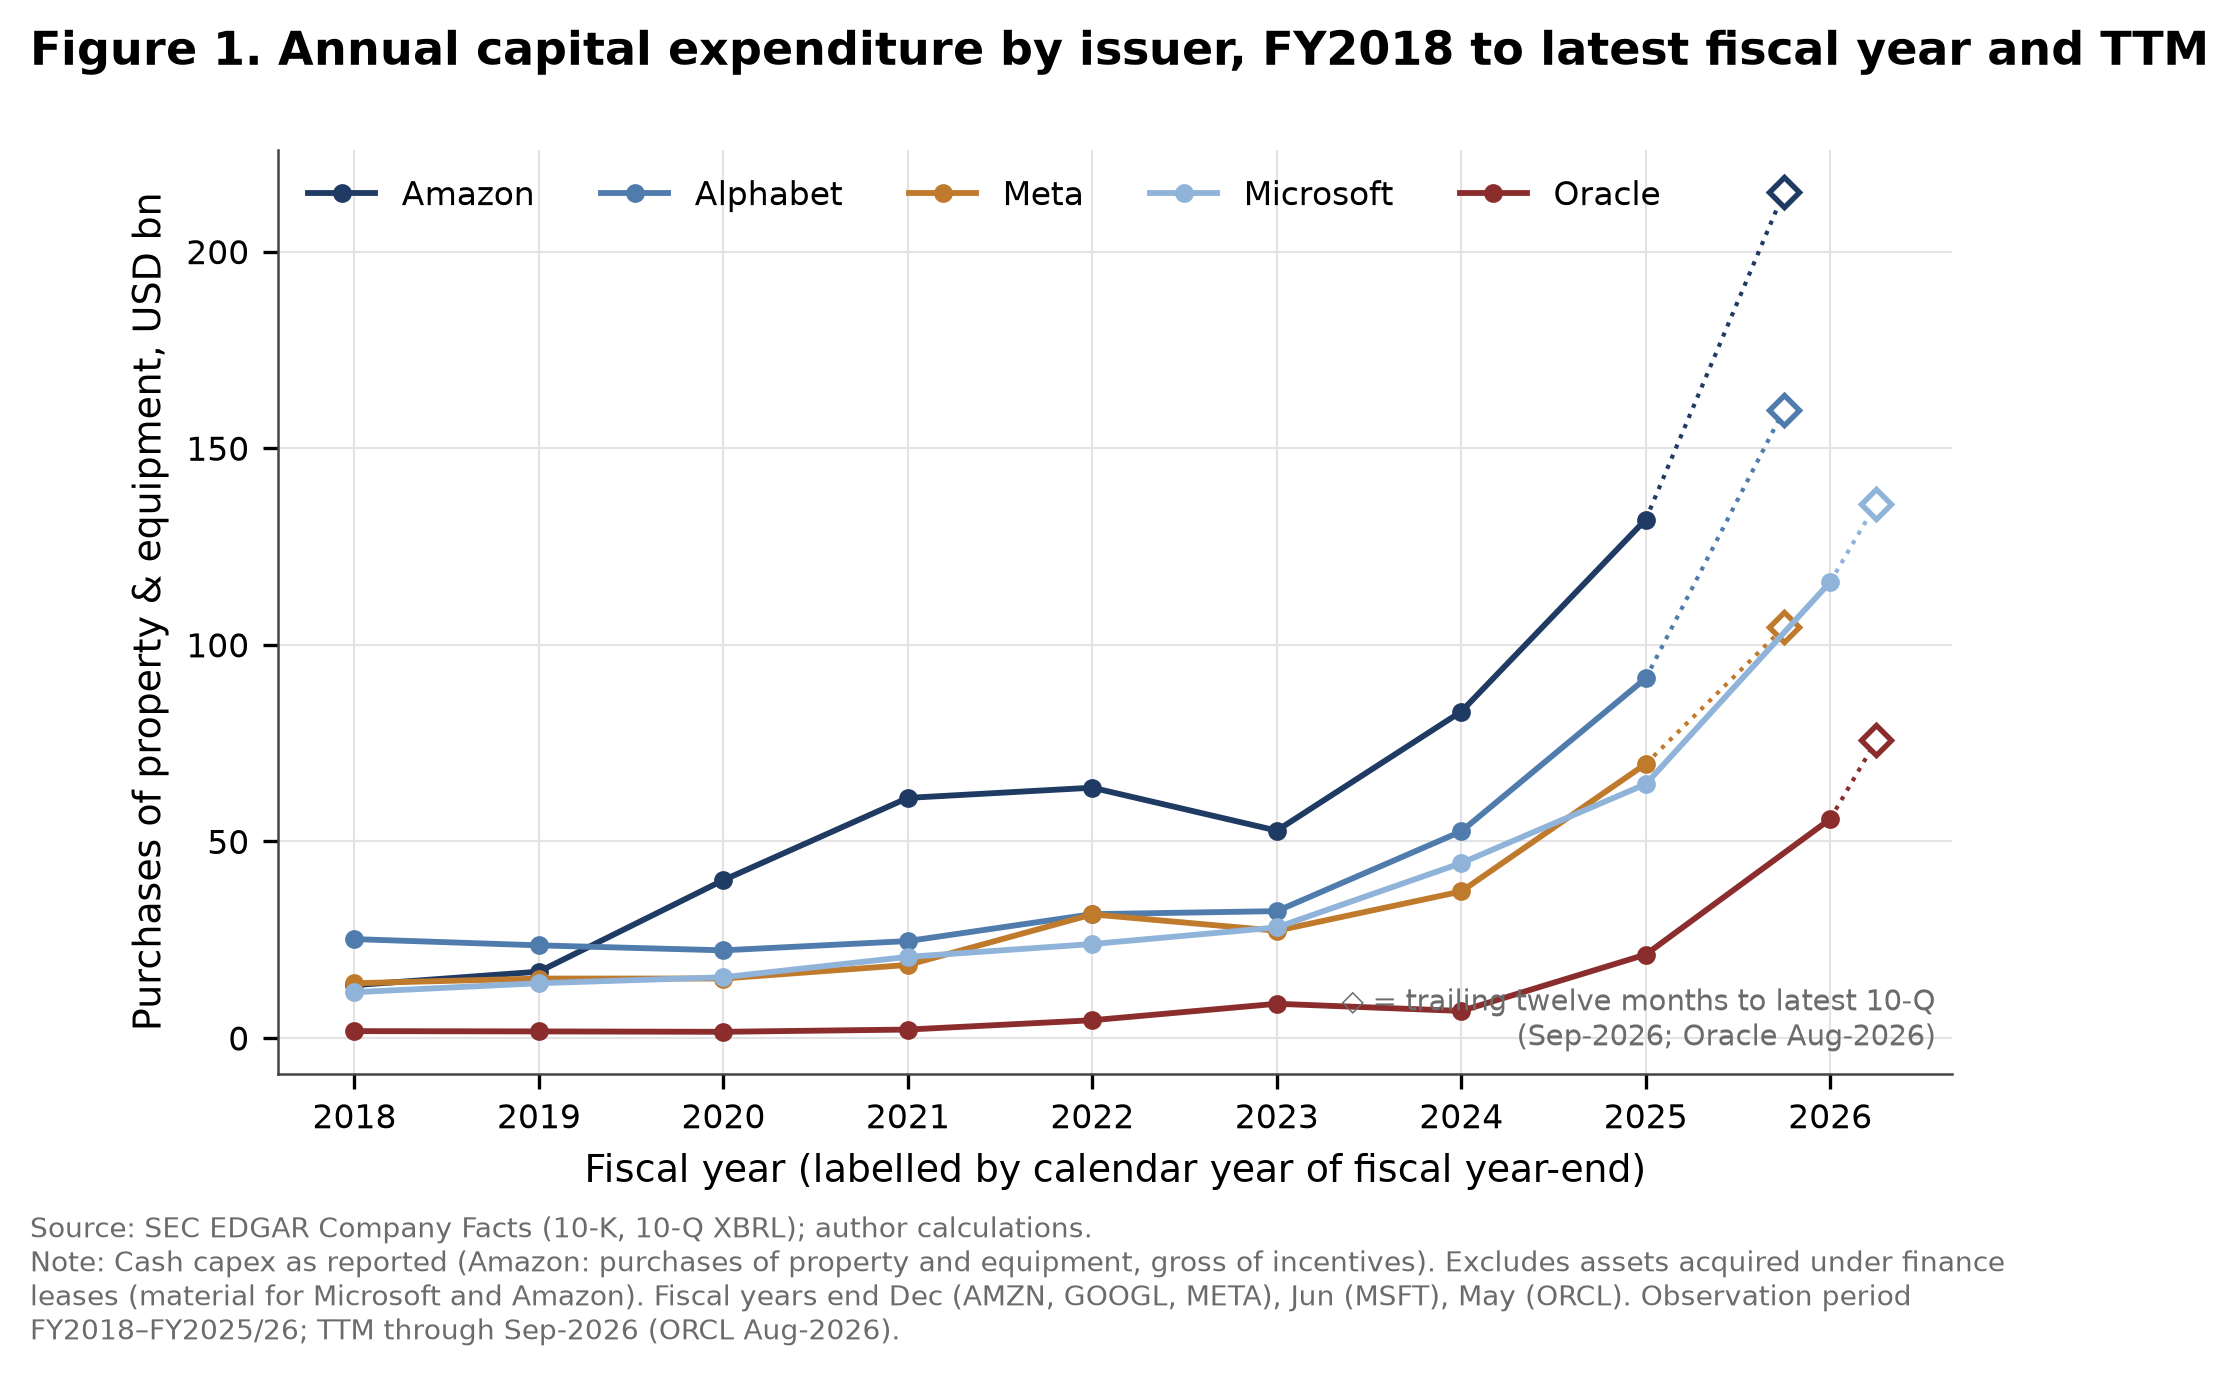

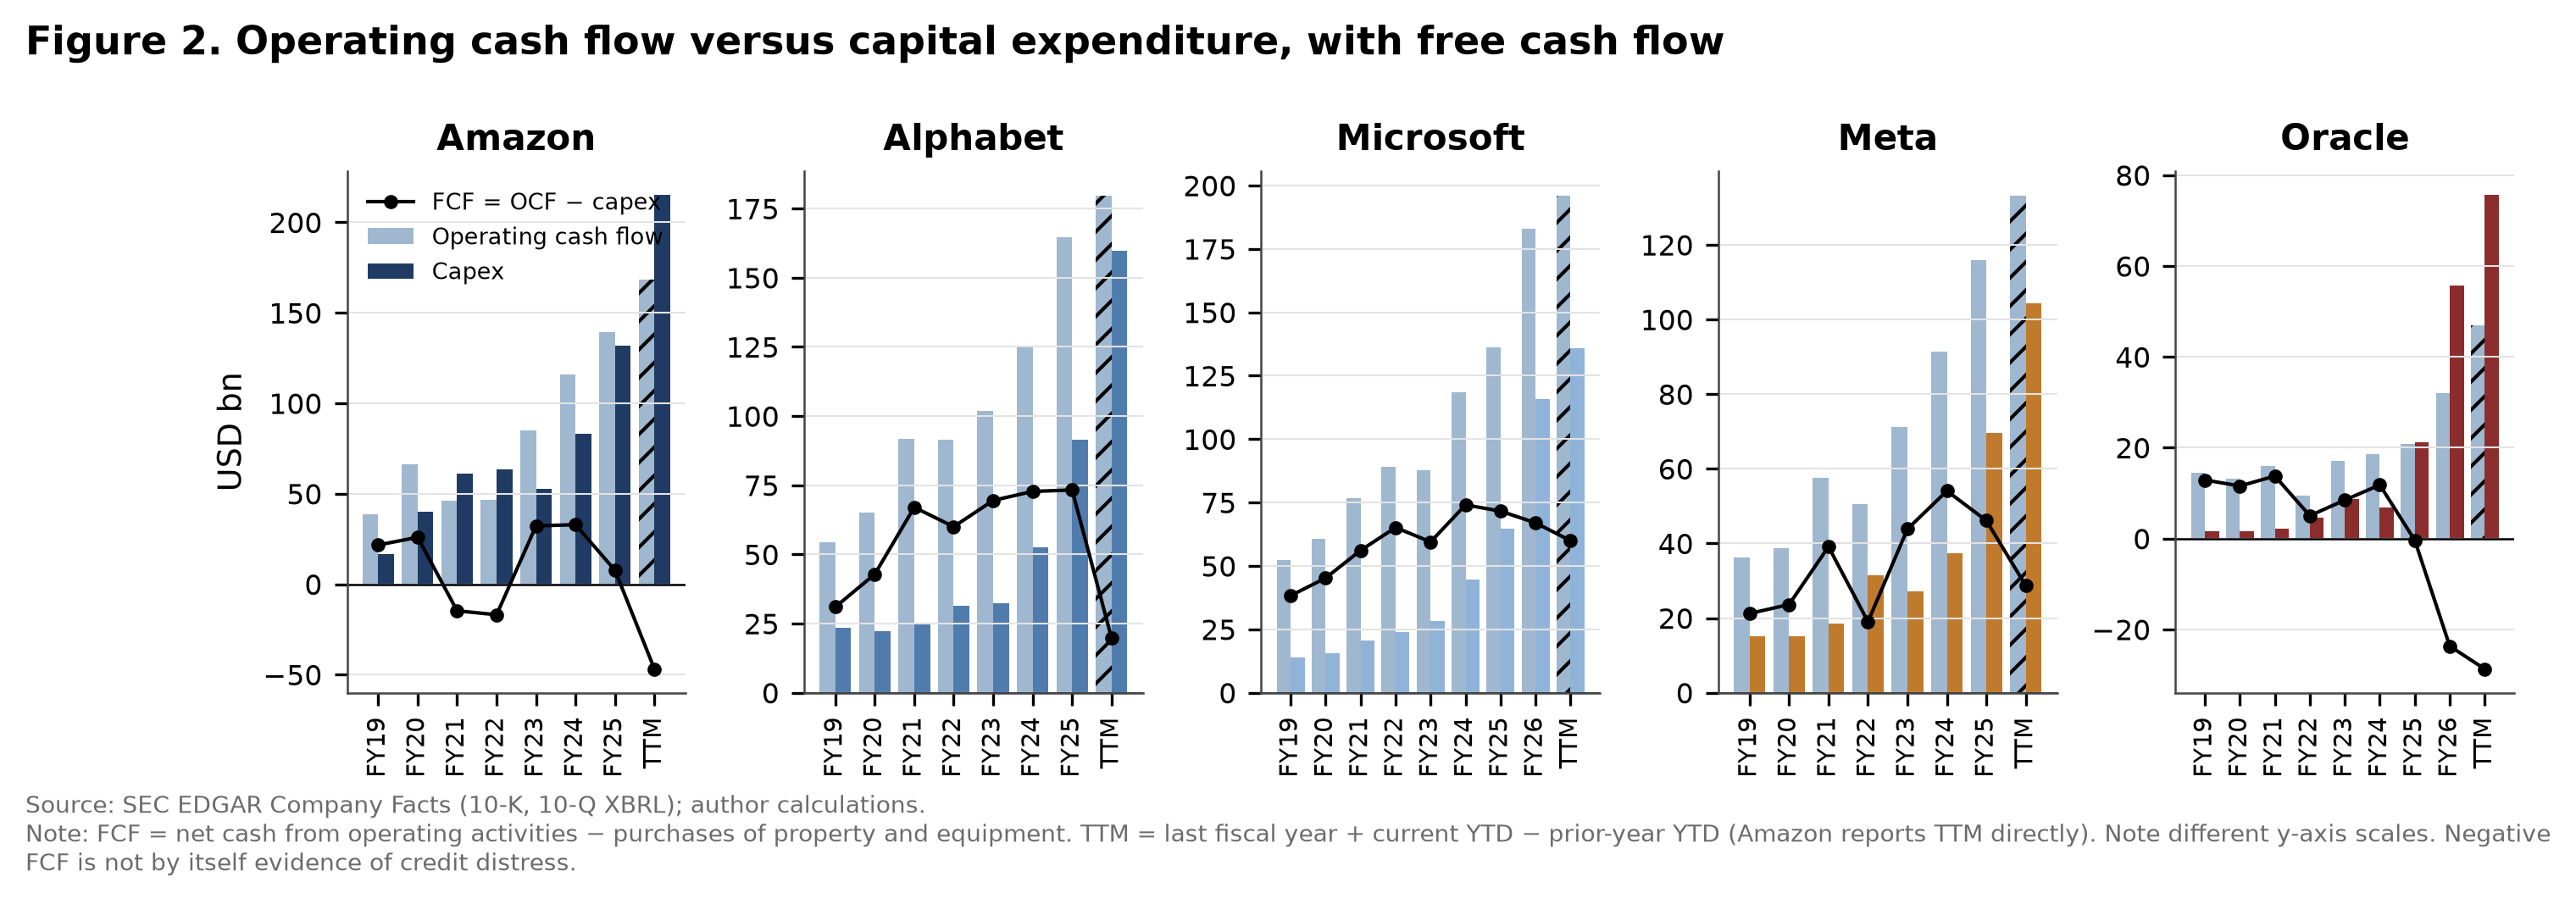

In [4]:
show_md('table1_issuer_characteristics'); show_fig('fig1_capex_by_issuer'); show_fig('fig2_ocf_vs_capex')

**Table 2. Liquidity, leverage and refinancing indicators**

| ticker | balance_sheet_date | cash_sti_bn | gross_debt_bn | debt_basis | finance_lease_liab_bn | net_debt_bn | net_debt_to_ttm_ebitda | gross_debt_incl_fin_leases_to_ttm_ebitda | ttm_ebitda_to_interest | maturities_next_12m_10k_bn | maturities_next_3y_10k_bn | cash_sti_to_next3y_maturities | ttm_fcf_less_next12m_maturities_bn | registered_issuance_after_fye_bn |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| AMZN | 2026-09-30 | 114.2 | 181.3 | principal (face) | 14.49 | 67.04 | 0.423 | 1.24 | 35.31 | 2.75 | 16.34 | 6.99 | -49.64 | 94.39 |
| GOOGL | 2026-09-30 | 265.1 | 127.5 | principal (face) | 3.71 | -137.6 | -0.744 | 0.709 | 60.13 | 2.00 | 5.68 | 46.71 | 17.75 | 79.68 |
| MSFT | 2026-09-30 | 64.51 | 41.27 | principal (face) | 70.97 | -23.24 | -0.115 | 0.557 | 62.52 | 9.25 | 11.25 | 5.73 | 50.71 | 25.00 |
| META | 2026-09-30 | 82.45 | 84.00 | principal (face) | 1.18 | 1.55 | 0.015 | 0.827 | 39.73 | 0.000 | 4.25 | 19.40 | 28.65 | 50.04 |
| ORCL | 2026-08-31 | 37.08 | 125.3 | carrying value | 9.19 | 88.26 | 2.72 | 4.14 | 6.36 | 7.21 | 22.86 | 1.62 | -35.93 | 10.00 |

Balance sheet at latest 10-Q (Sep-2026; ORCL Aug-2026). EBITDA = operating income + D&A (TTM). Maturities from latest 10-K contractual schedule (fiscal-year buckets) and therefore exclude debt issued after fiscal year-end. ORCL debt is carrying value (10-Q lacks principal tag); others principal + commercial paper.


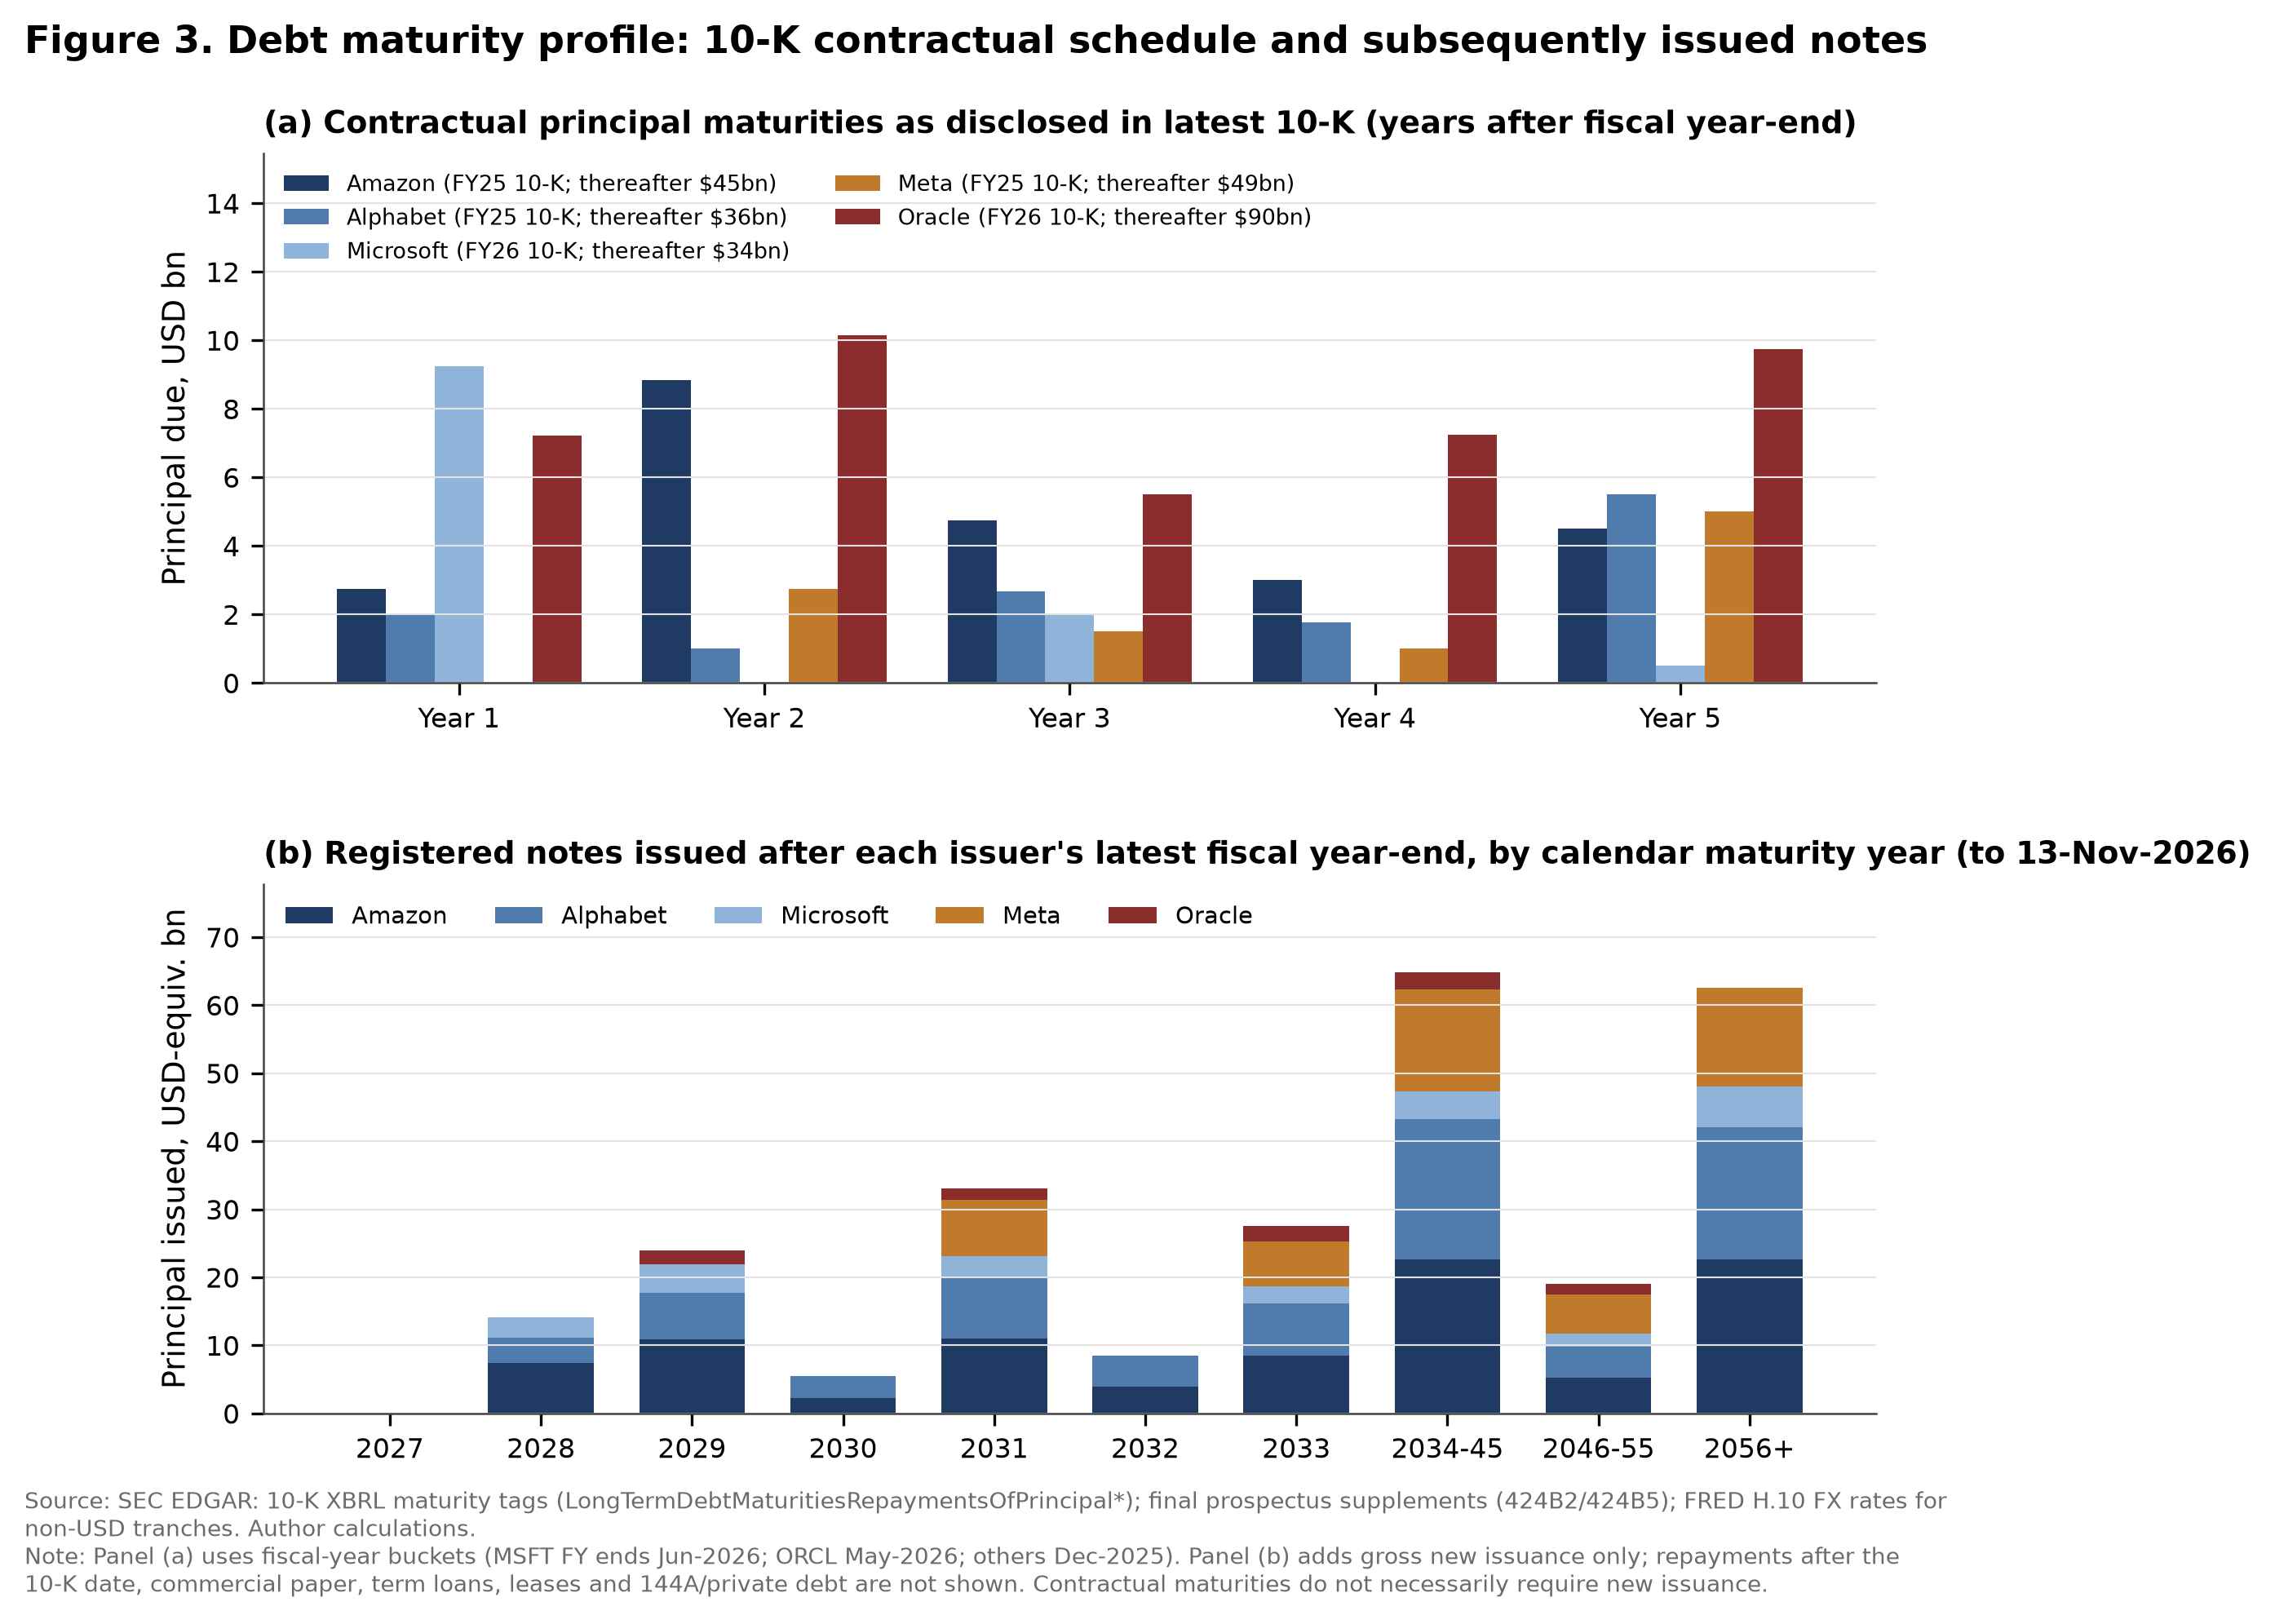

In [5]:
show_md('table2_liquidity_leverage_refinancing'); show_fig('fig3_debt_maturity_schedule')

In [6]:
pd.read_csv(ROOT/'data/processed/issuer_annual_10k_provenance.csv').head(30)

,ticker,item,end,value,unit,concept,form,accn,filed
0,AMZN,revenue,2017-12-31,177866000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-19-000004,2019-02-01
1,AMZN,revenue,2018-12-31,232887000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-19-000004,2019-02-01
2,AMZN,revenue,2019-12-31,280522000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-20-000004,2020-01-31
3,AMZN,revenue,2020-12-31,386064000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-21-000004,2021-02-03
4,AMZN,revenue,2021-12-31,469822000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-22-000005,2022-02-04
5,AMZN,revenue,2022-12-31,513983000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-23-000004,2023-02-03
6,AMZN,revenue,2023-12-31,574785000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-24-000008,2024-02-02
7,AMZN,revenue,2024-12-31,637959000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-25-000004,2025-02-07
8,AMZN,revenue,2025-12-31,716924000000,USD,RevenueFromContractWithCustomerExcludingAssess...,10-K,0001018724-26-000004,2026-02-06
9,AMZN,operating_cash_flow,2017-12-31,18434000000,USD,NetCashProvidedByUsedInOperatingActivities,10-K,0001018724-18-000005,2018-02-02
